<a href="https://colab.research.google.com/github/Patiencepaco/Housing-price-prediction-/blob/Rosemary-branch/ROSE-Testing-Models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Creating new features and testing models

Author: Edem Rose

We added 3 new features. Total features now: 16


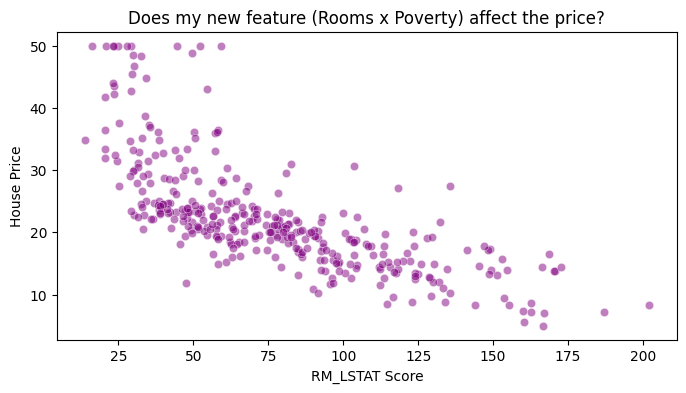


--- How did the models score? ---
Linear Regression: R2 = 0.644, RMSE = 6.166
Random Forest: R2 = 0.812, RMSE = 4.485
Gradient Boosting: R2 = 0.844, RMSE = 4.081

The winner is: Gradient Boosting


/tmp/ipykernel_1879/513192925.py:78: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importance.values, y=importance.index, palette="viridis")


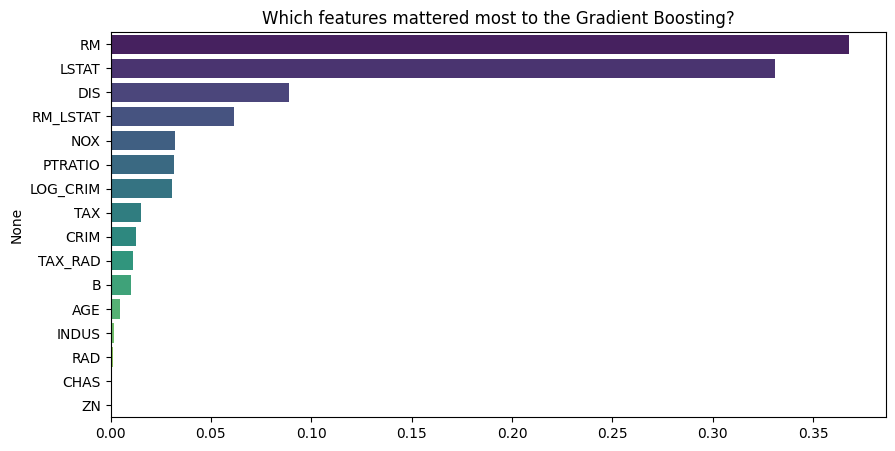


done!


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Loading the data
train = pd.read_csv("train.csv", index_col=0)
test = pd.read_csv("test.csv", index_col=0)

X = train.drop('MEDV', axis=1).copy()
y = train['MEDV']
X_test = test.copy()

# 1. Feature Engineering
# making new columns. Maybe a house with lots of rooms in a poor area is different than a house with lots of rooms in a rich area.
for df in [X, X_test]:
    df['RM_LSTAT'] = df['RM'] * df['LSTAT'] # Rooms multiplied by poverty level
    df['TAX_RAD'] = df['TAX'] / (df['RAD'] + 1) # Tax divided by highway access
    df['LOG_CRIM'] = np.log1p(df['CRIM']) # Crime data is squished to the left, so I'll log it

print("We added 3 new features. Total features now:", X.shape[1])

# Visual 1: check if the new RM_LSTAT feature is looks useful.
plt.figure(figsize=(8, 4))
sns.scatterplot(x=X['RM_LSTAT'], y=y, alpha=0.5, color='purple')
plt.title("Does my new feature (Rooms x Poverty) affect the price?")
plt.xlabel("RM_LSTAT Score")
plt.ylabel("House Price")
plt.show()

# 2. Scaling the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_test_scaled = scaler.transform(X_test)

# Splitting the data so I can test how good the models are
X_train, X_val, y_train, y_val = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# 3. testing a few different models to see which one is best.
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, random_state=42)
}

best_model_name = ""
best_r2 = 0
best_model = None

print("\n--- How did the models score? ---")
for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_val)

    # R2 tells us how accurate it is (1.0 is perfect)
    r2 = r2_score(y_val, preds)
    rmse = np.sqrt(mean_squared_error(y_val, preds))
    print(f"{name}: R2 = {r2:.3f}, RMSE = {rmse:.3f}")

    # I want to save the best one to use for the final submission
    if r2 > best_r2:
        best_r2 = r2
        best_model = model
        best_model_name = name

print(f"\nThe winner is: {best_model_name}")

# Visual 2: Why did the model make its choices?
best_model.fit(X_scaled, y)
importance = pd.Series(best_model.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x=importance.values, y=importance.index, palette="viridis")
plt.title(f"Which features mattered most to the {best_model_name}?")
plt.show()

# 4. Make the final predictions and save the file for Kaggle
final_preds = best_model.predict(X_test_scaled)
submission = pd.DataFrame({'ID': test.index, 'MEDV': final_preds})
submission.to_csv("submission.csv", index=False)
print("\ndone!")